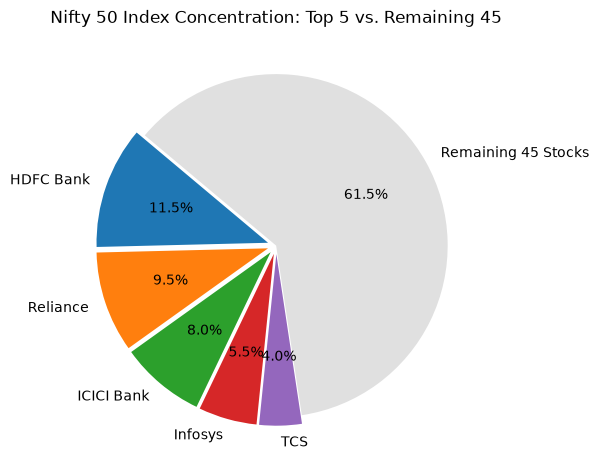

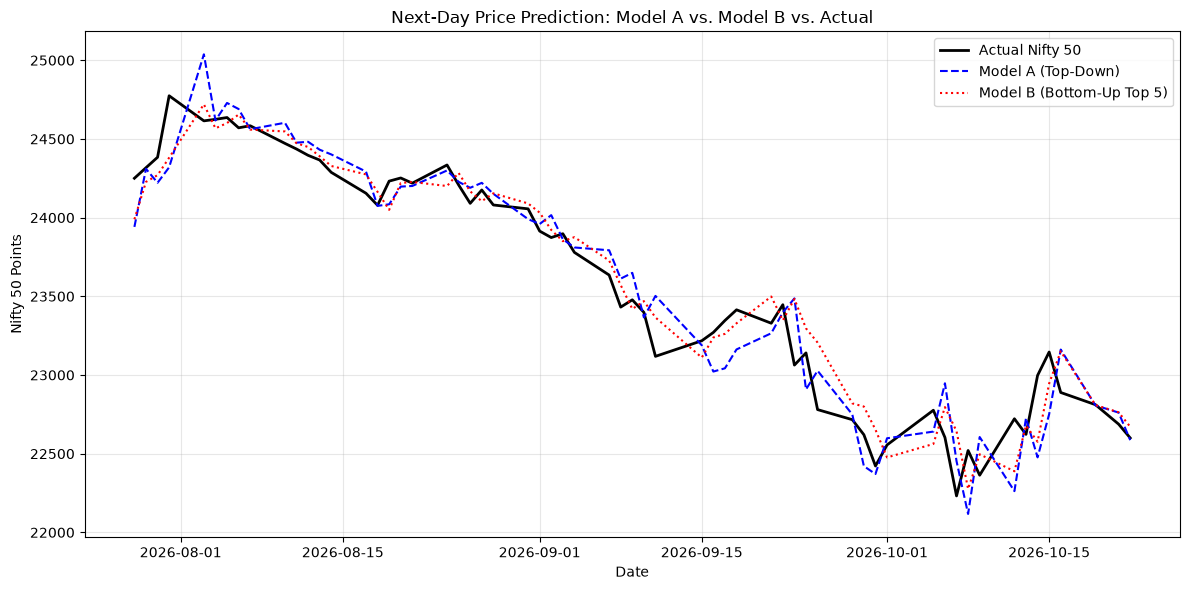

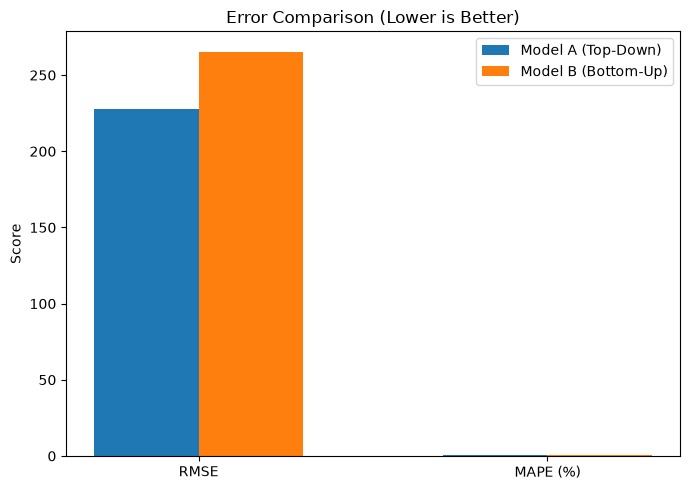

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# Load saved comparison results
df = pd.read_csv(
    "comparison_results_v2.csv", parse_dates=["Date"], index_col="Date"
)

# 1. PIE CHART: Market Cap Concentration
weights = {
    "HDFC Bank": 11.5,
    "Reliance": 9.5,
    "ICICI Bank": 8.0,
    "Infosys": 5.5,
    "TCS": 4.0,
    "Remaining 45 Stocks": 61.5,
}
plt.figure(figsize=(6, 6))
plt.pie(
    weights.values(),
    labels=weights.keys(),
    autopct="%1.1f%%",
    startangle=140,
    colors=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#e0e0e0"],
    explode=[0.05, 0.05, 0.05, 0.05, 0.05, 0],
)
plt.title("Nifty 50 Index Concentration: Top 5 vs. Remaining 45")
plt.tight_layout()
plt.savefig("nifty50_weights_pie.png", dpi=300)
plt.show()

# 2. LINE GRAPH: Actual vs Model A vs Model B (Last 60 Test Days)
subset = df.tail(60)
plt.figure(figsize=(12, 6))
plt.plot(
    subset.index, subset["Actual"], label="Actual Nifty 50", color="black", lw=2
)
plt.plot(
    subset.index,
    subset["TopDown_Pred"],
    label="Model A (Top-Down)",
    color="blue",
    linestyle="--",
)
plt.plot(
    subset.index,
    subset["BottomUp_Pred"],
    label="Model B (Bottom-Up Top 5)",
    color="red",
    linestyle=":",
)
plt.title("Next-Day Price Prediction: Model A vs. Model B vs. Actual")
plt.xlabel("Date")
plt.ylabel("Nifty 50 Points")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("forecast_comparison_line.png", dpi=300)
plt.show()

# 3. BAR CHART: Error Metric Comparison
metrics = ["RMSE", "MAPE (%)"]
model_A = [227.43, 0.70]
model_B = [265.47, 0.86]

x = range(len(metrics))
plt.figure(figsize=(7, 5))
plt.bar([i - 0.15 for i in x], model_A, width=0.3, label="Model A (Top-Down)")
plt.bar([i + 0.15 for i in x], model_B, width=0.3, label="Model B (Bottom-Up)")
plt.xticks(x, metrics)
plt.title("Error Comparison (Lower is Better)")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.savefig("error_metrics_bar.png", dpi=300)
plt.show()